# 12.6 Exercise — Random Forest (Fruit Basket)

**Question:** Consider the fruit basket. Multiple decision trees classify the same instance. Use majority voting to decide which fruit is likely to be taken often.

**Expected result from the reference figure:** Tree 1 predicts Apple, Tree 2 predicts Apple, and Tree n predicts Banana. Therefore, the final class is Apple (2 votes out of 3).

## 1. Importing Required Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn import tree
from sklearn.tree import plot_tree
from collections import Counter

## 2. Representing the votes shown in the question

In [2]:
tree_predictions = ['Apple', 'Apple', 'Banana']
vote_counts = Counter(tree_predictions)
print('Predictions from individual trees:', tree_predictions)
print('Vote counts:', dict(vote_counts))
final_class = vote_counts.most_common(1)[0][0]
print('Final class by majority voting:', final_class)

Predictions from individual trees: ['Apple', 'Apple', 'Banana']
Vote counts: {'Apple': 2, 'Banana': 1}
Final class by majority voting: Apple


## 3. Plotting the majority-voting bar chart

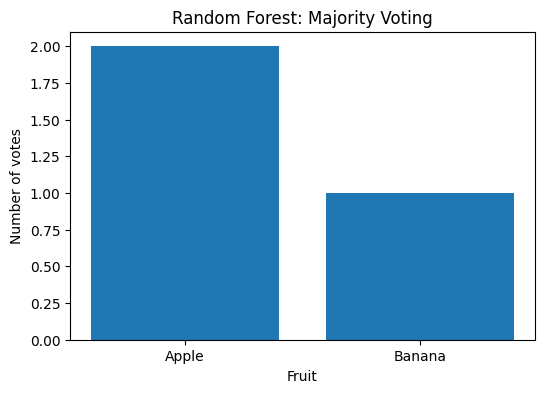

In [3]:
plt.figure(figsize=(6, 4))
plt.bar(vote_counts.keys(), vote_counts.values())
plt.xlabel('Fruit')
plt.ylabel('Number of votes')
plt.title('Random Forest: Majority Voting')
plt.show()

## 4. Training a Random Forest on an illustrative fruit dataset

The reference question does not provide numerical fruit measurements or a CSV dataset. The small dataset below is illustrative and is included only to demonstrate how scikit-learn trains a Random Forest and produces a decision-tree diagram.

In [4]:
data = pd.DataFrame({
    'weight_g': [150, 170, 140, 160, 180, 130, 120, 135, 125, 145, 155, 165, 118, 128, 138, 172, 182, 158, 122, 132],
    'sweetness': [7, 8, 6, 7, 8, 6, 9, 8, 9, 7, 8, 7, 9, 8, 8, 7, 8, 6, 9, 8],
    'yellow_score': [1, 1, 0, 0, 1, 0, 9, 8, 9, 8, 0, 1, 9, 8, 8, 1, 0, 0, 9, 8],
    'fruit': ['Apple', 'Apple', 'Apple', 'Apple', 'Apple', 'Apple', 'Banana', 'Banana', 'Banana', 'Banana',
              'Apple', 'Apple', 'Banana', 'Banana', 'Banana', 'Apple', 'Apple', 'Apple', 'Banana', 'Banana']
})
data.head()

,weight_g,sweetness,yellow_score,fruit
0,150,7,1,Apple
1,170,8,1,Apple
2,140,6,0,Apple
3,160,7,0,Apple
4,180,8,1,Apple


## 5. Assigning independent and dependent variables

In [5]:
X = data.iloc[:, :-1]
y = data.iloc[:, -1]

## 6. Fitting the Random Forest Classifier

In [6]:
model = RandomForestClassifier(n_estimators=3, criterion='entropy', random_state=0, max_depth=3)
model.fit(X, y)
print('Random Forest model trained.')

Random Forest model trained.


## 7. Visualizing one decision tree formed

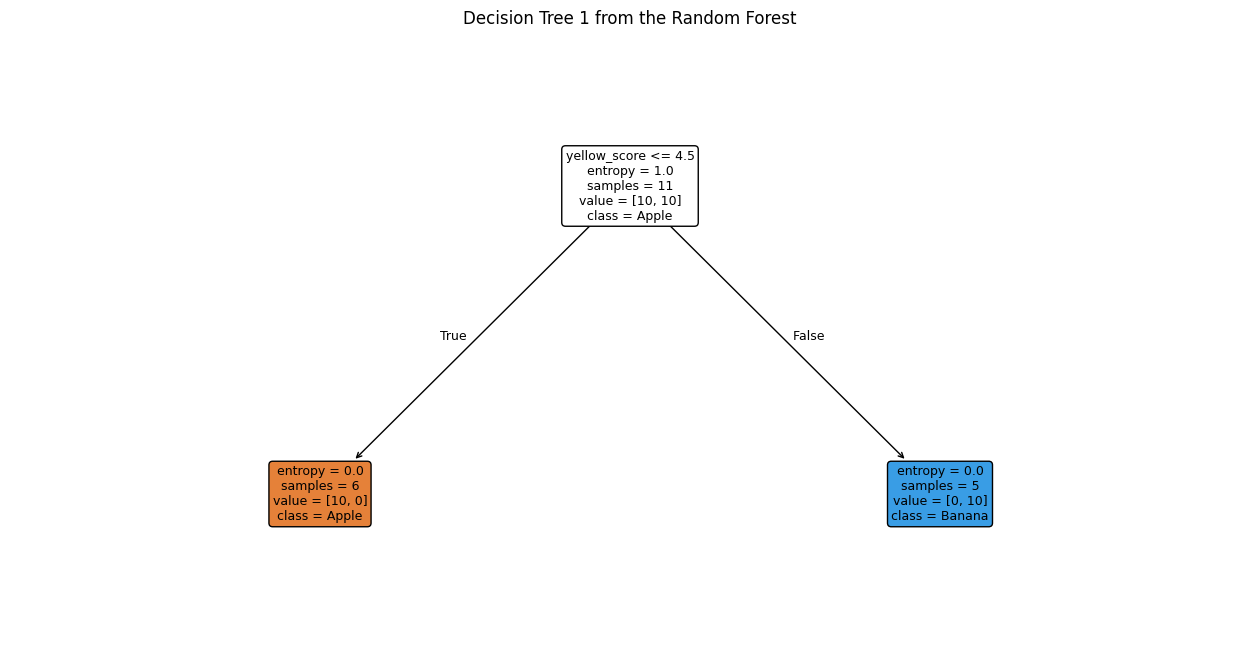

In [7]:
plt.figure(figsize=(16, 8))
plot_tree(
    model.estimators_[0],
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    impurity=True,
    fontsize=9
)
plt.title('Decision Tree 1 from the Random Forest')
plt.show()

## 8. Predicting a sample and viewing individual tree votes

In [8]:
new_fruit = pd.DataFrame([{'weight_g': 155, 'sweetness': 7, 'yellow_score': 0}])
individual_votes = [estimator.predict(new_fruit)[0] for estimator in model.estimators_]
print('New fruit features:')
display(new_fruit)
print('Votes from the trained trees:', individual_votes)
print('Vote counts:', dict(Counter(individual_votes)))
print('Random Forest prediction:', model.predict(new_fruit)[0])

New fruit features:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


,weight_g,sweetness,yellow_score
0,155,7,0


Votes from the trained trees: [np.float64(0.0), np.float64(0.0), np.float64(0.0)]
Vote counts: {np.float64(0.0): 3}
Random Forest prediction: Apple


## 9. Evaluation Metrics, Confusion Matrix, and Heatmap

Split the illustrative dataset into training and testing sets, train the Random Forest on the training data, and evaluate its predictions on the unseen test data. This avoids evaluating the model only on data it has already seen.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import seaborn as sns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

eval_model = RandomForestClassifier(
    n_estimators=100, criterion='entropy', random_state=42
)
eval_model.fit(X_train, y_train)
y_pred = eval_model.predict(X_test)

print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('\nClassification Report:\n')
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8333

Classification Report:

              precision    recall  f1-score   support

       Apple       0.75      1.00      0.86         3
      Banana       1.00      0.67      0.80         3

    accuracy                           0.83         6
   macro avg       0.88      0.83      0.83         6
weighted avg       0.88      0.83      0.83         6



### Confusion Matrix

In [10]:
labels = eval_model.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)
print('Confusion Matrix:\n', cm)

Confusion Matrix:
 [[3 0]
 [1 2]]


### Confusion Matrix Heatmap

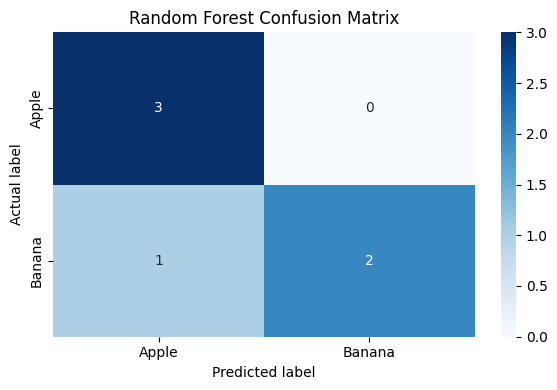

In [11]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Random Forest Confusion Matrix')
plt.tight_layout()
plt.show()

## Conclusion

**Answer to the given exercise: Apple.** In the supplied figure, two trees predict Apple and one predicts Banana. Majority voting selects Apple. The trained model and its tree visualization use an illustrative dataset because the exercise image does not provide actual fruit feature data.